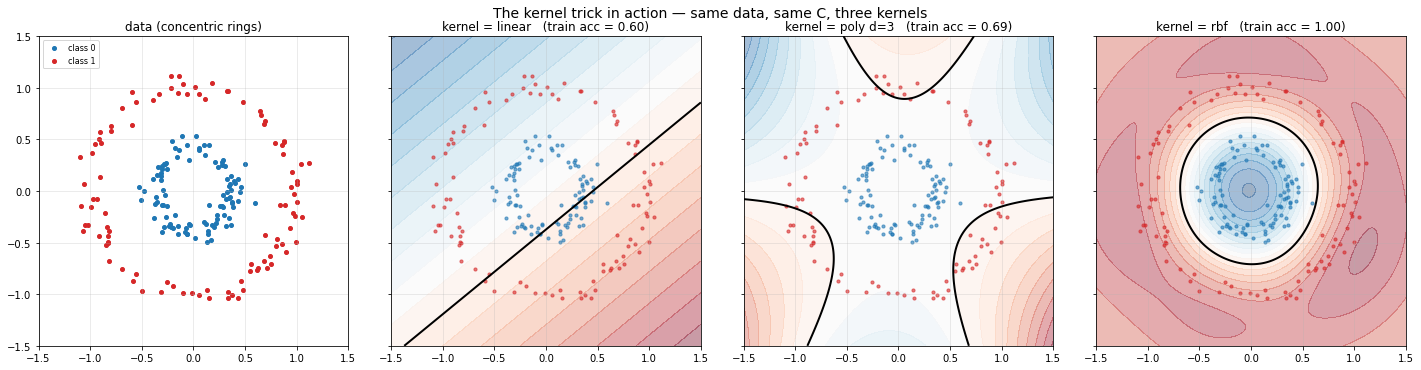

linear  min eigenvalue = -6.458e-15   PSD = True
  poly  min eigenvalue = -1.645e-14   PSD = True
   rbf  min eigenvalue = +2.719e-10   PSD = True
<x,x'>-check  lhs=1.361671   rhs=1.361671   match=True
<x,x'>-check  lhs=7.278753   rhs=7.278753   match=True
<x,x'>-check  lhs=3.709220   rhs=3.709220   match=True
<x,x'>-check  lhs=5.930967   rhs=5.930967   match=True
<x,x'>-check  lhs=17.154544   rhs=17.154544   match=True


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC

rng = np.random.default_rng(0)

# ----------------------------------------------------------------------
# 1. Data: two concentric rings (non-linearly separable)
# ----------------------------------------------------------------------
def sample_rings(n=200, noise=0.08, r_in=0.4, r_out=1.0):
    n_in = n // 2
    n_out = n - n_in
    t_in  = rng.uniform(0, 2*np.pi, n_in)
    t_out = rng.uniform(0, 2*np.pi, n_out)
    X_in  = np.c_[(r_in  + rng.normal(0, noise, n_in)) * np.cos(t_in),
                  (r_in  + rng.normal(0, noise, n_in)) * np.sin(t_in)]
    X_out = np.c_[(r_out + rng.normal(0, noise, n_out)) * np.cos(t_out),
                  (r_out + rng.normal(0, noise, n_out)) * np.sin(t_out)]
    X = np.vstack([X_in, X_out])
    y = np.r_[np.zeros(n_in, int), np.ones(n_out, int)]
    perm = rng.permutation(n)
    return X[perm], y[perm]

X, y = sample_rings()

# Dense grid for decision-function heatmaps
gx, gy = np.meshgrid(np.linspace(-1.5, 1.5, 300),
                     np.linspace(-1.5, 1.5, 300))
X_test = np.c_[gx.ravel(), gy.ravel()]

# ----------------------------------------------------------------------
# 2. Three SVMs, one per kernel — SAME data, SAME C
# ----------------------------------------------------------------------
C = 1.0
models = {
    "linear":  SVC(kernel="linear", C=C),
    "poly d=3": SVC(kernel="poly",   degree=3, gamma="scale", C=C),
    "rbf":     SVC(kernel="rbf",    gamma=2.0, C=C),
}

fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharex=True, sharey=True)

# raw data
ax = axes[0]
ax.scatter(X[y==0, 0], X[y==0, 1], s=16, color="C0", label="class 0")
ax.scatter(X[y==1, 0], X[y==1, 1], s=16, color="C3", label="class 1")
ax.set_title("data (concentric rings)")
ax.set_aspect("equal"); ax.set_xlim(-1.5, 1.5); ax.set_ylim(-1.5, 1.5)
ax.legend(fontsize=8, loc="upper left"); ax.grid(alpha=0.3)

for ax, (name, clf) in zip(axes[1:], models.items()):
    clf.fit(X, y)
    Z = clf.decision_function(X_test).reshape(gx.shape)
    ax.contourf(gx, gy, Z, levels=20, cmap="RdBu_r", alpha=0.4)
    ax.contour(gx, gy, Z, levels=[0], colors="k", linewidths=2)
    ax.scatter(X[y==0, 0], X[y==0, 1], s=10, color="C0", alpha=0.6)
    ax.scatter(X[y==1, 0], X[y==1, 1], s=10, color="C3", alpha=0.6)
    acc = clf.score(X, y)
    ax.set_title(f"kernel = {name}   (train acc = {acc:.2f})")
    ax.set_aspect("equal"); ax.set_xlim(-1.5, 1.5); ax.set_ylim(-1.5, 1.5)
    ax.grid(alpha=0.3)

fig.suptitle("The kernel trick in action — same data, same C, three kernels",
             fontsize=14)
fig.tight_layout()
plt.show()

# %% [markdown]
# ## What you just saw
#
# - **linear kernel** — the decision boundary is a straight line. Rings are
#   not linearly separable, so accuracy is poor. The SVM cannot do better
#   without a *new representation*.
# - **polynomial kernel (d=3)** — the boundary is a cubic algebraic curve.
#   It can bend, and starts capturing part of the ring structure, but the
#   extra flexibility is in the wrong directions (monomials of $x,y$).
# - **RBF kernel** — the boundary **wraps around** the inner ring. Accuracy
#   ≈ 1. The model behaves as if the data lived in a much richer space where
#   a hyperplane *can* separate them — which is exactly what the kernel
#   trick provides.
#
# Crucially, in all three cases `SVC` runs the **same** algorithm (SMO on
# the dual). The only difference is the function `k(x, x')` used inside.

# %% [markdown]
# ## Why the RBF kernel is (secretly) an inner product
#
# Expand
#
# $$
# k(x,x') = e^{-\gamma\|x-x'\|^2}
#        = e^{-\gamma\|x\|^2}\, e^{-\gamma\|x'\|^2}\, e^{2\gamma\langle x,x'\rangle}.
# $$
#
# Using $e^{z}=\sum_{n\ge 0} z^n/n!$ with $z = 2\gamma\langle x,x'\rangle$:
#
# $$
# k(x,x') = e^{-\gamma(\|x\|^2+\|x'\|^2)}
# \sum_{n=0}^{\infty}\frac{(2\gamma)^n}{n!}\langle x,x'\rangle^n .
# $$
#
# Each $\langle x,x'\rangle^n$ expands into monomials of degree $n$. So
# there exists an *infinite-dimensional* feature map $\phi(x)$ with
# $k(x,x')=\langle\phi(x),\phi(x')\rangle$, and the SVM never has to build it.
#
# On a **finite grid** we can check this numerically: pick $N$ points,
# evaluate the kernel matrix $K_{ij}=k(x_i,x_j)$, and verify it is positive
# semi-definite — i.e. it **is** a Gram matrix of some feature map.

# %%
# ----------------------------------------------------------------------
# 3. Verify numerically that each kernel gives a valid (PSD) Gram matrix
# ----------------------------------------------------------------------
def kernel_matrix(kfunc, X):
    return np.array([[kfunc(a, b) for b in X] for a in X])

linear = lambda a, b: np.dot(a, b)
poly   = lambda a, b: (1.0 + np.dot(a, b)) ** 3
rbf    = lambda a, b: np.exp(-2.0 * np.sum((a - b) ** 2))

for name, kf in [("linear", linear), ("poly", poly), ("rbf", rbf)]:
    K = kernel_matrix(kf, X[:60])
    eigs = np.linalg.eigvalsh((K + K.T) / 2)   # symmetric part
    print(f"{name:>6}  min eigenvalue = {eigs.min():+.3e}   "
          f"PSD = {eigs.min() > -1e-8}")

# %% [markdown]
# ## Explicit feature map for the polynomial kernel
#
# For degree $p=2$ in 2D, the polynomial kernel
# $k(x,x')=(1+\langle x,x'\rangle)^2$ corresponds exactly to
#
# $$
# \phi(x) = \big(1,\ \sqrt2\,x_1,\ \sqrt2\,x_2,\ x_1^2,\ \sqrt2\,x_1x_2,\ x_2^2\big)^\top
# $$
#
# — a map to $\mathbb{R}^6$. Let's verify that
# $\langle\phi(x),\phi(x')\rangle = (1+\langle x,x'\rangle)^2$.

# %%
# ----------------------------------------------------------------------
# 4. Explicit polynomial feature map: (1 + <x,x'>)^2 == <phi(x),phi(x')>
# ----------------------------------------------------------------------
def phi_poly2(x):
    x1, x2 = x
    return np.array([1.0,
                     np.sqrt(2) * x1,
                     np.sqrt(2) * x2,
                     x1 * x1,
                     np.sqrt(2) * x1 * x2,
                     x2 * x2])

# random check
for _ in range(5):
    a = rng.normal(size=2)
    b = rng.normal(size=2)
    lhs = (1.0 + a @ b) ** 2
    rhs = phi_poly2(a) @ phi_poly2(b)
    print(f"<x,x'>-check  lhs={lhs:.6f}   rhs={rhs:.6f}   "
          f"match={np.isclose(lhs, rhs)}")

# %% [markdown]
# ## Takeaway
#
# The kernel trick is not a different learning algorithm — it is a
# **change of inner product**. Swap $k(x,x')=\langle x,x'\rangle$ for any
# positive semi-definite kernel and, *without changing a single line of the
# SVM code*, you are suddenly learning in an entirely different feature
# space. The RBF kernel sends you to an infinite-dimensional one — which is
# never materialized, only queried.
#
# The same trick underlies Gaussian processes, kernel ridge regression,
# kernel PCA, and many other methods.